# Calibration procedure of 1.4 GHz Radio Telescope using a Sun Drift

When using a radio telescope the raw measurement we receive is in arbitrary units. The aim of this notebook is to convert the arbitrary units into physical units. Because of the Rayleigh-Jeans relation $$P=k_B T \Delta \nu,$$ we can express the radio power in the units of a temperature, we call it antenna temperature, and it's usually measured in Kelvin.

To do so, a simple technique is to observe the Sun drifting into the field of view of the telescope. Because of the Sun's movement we don't need any movement of the telescope. We only need to point it ahead of time to some coordinates belonging to the Sun's trajectory.

The Sun drifting into the field of view of the telescope will draw a Gaussian for which we can fit the parameters. Once we know the baseline of the gaussian and it's peak, we can subtracty them and obtain the pure radio signal of the Sun, in fact the baseline of the gaussian which we remove, represents all the noise (both internal to the receiver and of the sky). This would be still in arbitrary units. However the radio signal of the Sun is measured daily and reported in many archives. One of them can be found here: https://www.spaceweather.gc.ca/forecast-prevision/solar-solaire/solarflux/sx-5-flux-en.php.  
What is reported in that website actually is the flux in 2.8 GHz (or 10.7 cm ) but it can be converted to the flux in 1.4 GHz using the following relation: $$F_{1.4} = \left(\frac{1.4}{2.8}\right)^{0.7}F_{2.8}$$ (the index 0.7 can reach 1.1 at a solar maximum of activity). Moreover the units used are Solar Flux Unit (SFU) which are: $$1\, \rm{SFU} = 10^{-22} \frac{W}{m^2 \,\rm{Hz}}$$

The expected antenna temperature of the Sun, given it's flux in $W m^{-2} \rm{Hz}^-1$ is: $$T_{\rm{Sun}}= \frac{F_{1.4}\cdot A_e}{2 \cdot k_b} $$ where $A_e$ is the effective collecting area of the telescope which is usually $60 \%$ of the total area $\pi (D/2)^2$, whith $D$ being the diameter of the telescope, in our case $D=3m$.

The antenna temperature of the Sun corresponds to the change in counts due to the drift of the Sun in the field of view. This means that we can find can find the conversion factor simply by dividing the Sun antenna temperature by the amplitude of the gaussian that we previosly fitted. This quantity is usually called gain and indicated with K: $$ K = \frac{T_{Sun}}{\Delta P},$$ where we used $\Delta P$ for the gauusian amplitude as that's the variation of the radio power in arbitrary units.

Once we have that number which has the units of $\rm{Kelvin}/ \rm{counts}$ we just needs to multiply the raw counts by that number to obtain the antenna temperature in Kelvin.

The antenna temperature is representative of the temperature brightness of the source only when we are looking at an extended source that is much bigger than the anteanna beam. In our case the Sun has a diameter of only 0.5 deg while the antenna beam is approximately 4.6 deg. This means that the signal is diluated all over the dish. To get the proper temperature brightness we need to scale the antenna temperature by the ratios of the two solid angles (of the antenna beam and the source). To be precise we can also consider the antenna beam efficiency that is usually around $\eta_{\rm{MB}}\approx 60\%$:

$$ T_B = \frac{T_A}{\eta_{\rm{MB}}} \cdot \frac{\Omega_A}{\Omega_S}$$

In [1]:
!wget -O radio_utilities.py "https://raw.githubusercontent.com/GiorgioManzoni/RADIO14GHZ/refs/heads/master/radio_utilities.py"
!wget -O 20260622_SUN.fits "https://raw.githubusercontent.com/GiorgioManzoni/RADIO14GHZ/refs/heads/master/20260622_SUN.fits"

--2026-08-04 04:15:20--  https://raw.githubusercontent.com/GiorgioManzoni/RADIO14GHZ/refs/heads/master/radio_utilities.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.110.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3941 (3.8K) [text/plain]
Saving to: ‘radio_utilities.py’

radio_utilities.py  100%[===================>]   3.85K  --.-KB/s    in 0s      

2026-08-04 04:15:21 (36.6 MB/s) - ‘radio_utilities.py’ saved [3941/3941]

--2026-08-04 04:15:21--  https://raw.githubusercontent.com/GiorgioManzoni/RADIO14GHZ/refs/heads/master/20260622_SUN.fits
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response...

In [2]:
from radio_utilities import *

In [16]:
with fits.open('20260622_SUN.fits') as hdul:
    astro_table = Table(hdul[1].data)
    data = astro_table.to_pandas()

x = data['JD']
#y = data['RIGHT_POL'].values
y = data['LEFT_POL'].values

DIAMETER =                    0  / TELESCOPE diameter                            [astropy.io.fits.card]
DIAMETER =                    0  / TELESCOPE diameter                           


In [17]:
beam = get_beam_angle(x,y)
print('Main beam angle: %.2f deg'%beam)

Main beam angle: 4.59 deg


### Gaussian Fit ###
Amplitude 34.907449112623674
Centre [Julian date] 2461213.747372063
Sigma [Days] 0.005672094437780851
Sigma [min] 8.167815990404426
Background floor [adu] 20.662229460292014
FWHM [days] 0.013356761423975105
FWHM [min] 19.23373645052415
Estimated antenna beam with 0.25 deg/min 4.808434112631038


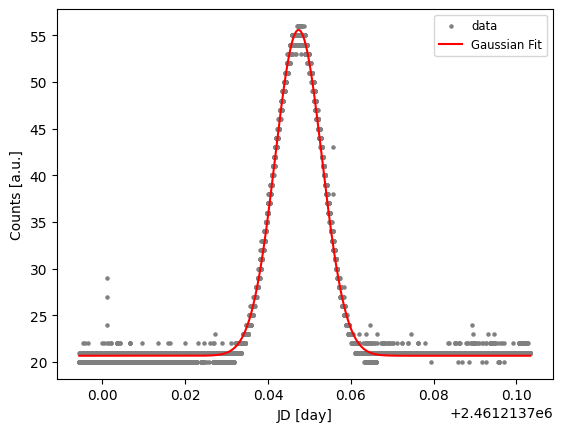

In [18]:
Amp_adu, centre_jd, sigma_jd, floor_adu, fwhm_day =  gauss_fit(x,y,verbose=True,plot=True)

In [19]:
def get_conversion_K(julian_dates, counts_adu, amp_adu, solar_flux_sfu, aperture_eff=0.60):
    k_B = 1.38e-23  # Boltzmann constant [J/K]
    dish_diameter = 3.0  # Dish diameter in meters


    # Calculate Effective Aperture
    A_geom = np.pi * (dish_diameter / 2) ** 2
    A_e = aperture_eff * A_geom

    # Convert SFU to W/m^2/Hz
    S_flux = solar_flux_sfu * 1e-22

    # Expected Antenna Temperature of the Sun
    T_sun_expected = (S_flux * A_e) / (2 * k_B)

    # Calculate Calibration Factor K
    K = T_sun_expected / amp_adu

    return K

In [20]:
# NOAA's live JSON feed for daily F10.7 flux measurements
url = "https://services.swpc.noaa.gov/json/f107_cm_flux.json"
# Load directly into a Pandas DataFrame
df_daily = pd.read_json(url)
# Convert timestamp column to datetime
df_daily['time_tag'] = pd.to_datetime(df_daily['time_tag'])
# estimate Flux F10.7 (2.8GHz) on a specific date
f107 = (df_daily[df_daily['time_tag']=='2026-07-22 17:00:00']['flux']).values[0]
print('Flux on 2026-07-22 22:00:00 at 10.7 cm: ',f107)
#Alternatively f107 can be found at

f14 = f107*(1.4/2.8)**0.8 # (1.4/2.8)**0.8=0.574
print('Flux on 2026-07-22 22:00:00 at 1.4 GHz: ',f14)
K = get_conversion_K(x,y,amp_adu=Amp_adu,solar_flux_sfu=f14)

print('Conversion factor between ADU to Antenna temperature: ',K)

Flux on 2026-07-22 22:00:00 at 10.7 cm:  150.0
Flux on 2026-07-22 22:00:00 at 1.4 GHz:  86.15237662477762
Conversion factor between ADU to Antenna temperature:  37.9248357063362


# Plot antenna Temperature

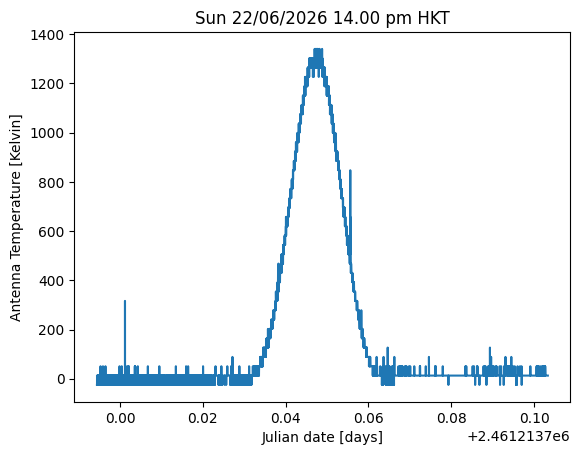

In [21]:
AntennaTemp = (y-floor_adu)*K

plt.plot(x, AntennaTemp)
plt.xlabel('Julian date [days]')
plt.ylabel('Antenna Temperature [Kelvin]')
plt.title('Sun 22/06/2026 14.00 pm HKT')

plt.show()

# Convert to temperature Brightness

In [22]:
def ta_to_tb(T_A, beamwidth_deg=4.6, source_deg=0.553, eta_mb=0.7):
    """
    Converts Antenna Temperature to Brightness Temperature using a measured beamwidth.
    """
    # Convert measured beamwidth to radians
    theta_beam_rad = np.radians(beamwidth_deg)

    # Gaussian beam solid angle of the telescope
    omega_A = 1.133 * (theta_beam_rad ** 2)

    # Source solid angle (~0.533 degrees diameter for the Sun)
    theta_source_rad = np.radians(0.533)
    omega_source = np.pi * (theta_source_rad / 2) ** 2

    # Dilution ratio
    dilution_ratio = omega_A / omega_source

    # Intrinsic Brightness Temperature
    T_B = (T_A / eta_mb) * dilution_ratio

    return T_B

In [23]:
BrightnessTemp = ta_to_tb(AntennaTemp,beamwidth_deg=beam)

# Plot Temperature Brightness

Temperature Brightness (peak) =  205125.25088085714


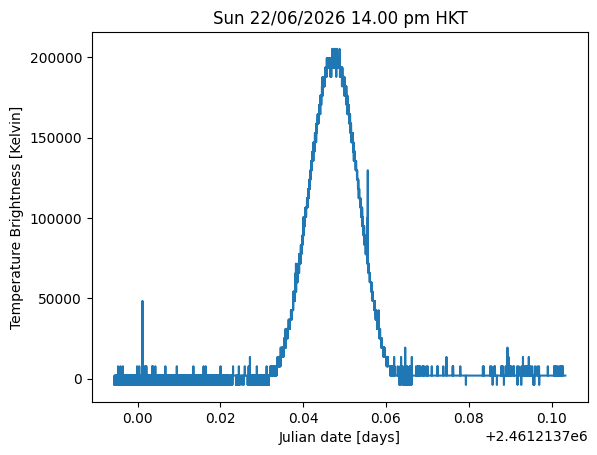

In [24]:
plt.plot(x, BrightnessTemp)
plt.xlabel('Julian date [days]')
plt.ylabel('Temperature Brightness [Kelvin]')
plt.title('Sun 22/06/2026 14.00 pm HKT')
print('Temperature Brightness (peak) = ',BrightnessTemp.max() )
plt.show()